# Libraries

In [14]:
import json
import os

from etils import epath
from pathlib import Path
import pandas as pd
import numpy as np
import tensorflow_datasets.public_api as tfds
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import tensorflow as tf
import tarfile
import random
from PIL import Image
import matplotlib.pyplot as plt
import plotly.express as px

# Descarga del dataset mini

In [2]:
# Descargar y cargar el dataset MNIST
ds = tfds.load('mnist', split='train', shuffle_files=True)
assert isinstance(ds, tf.data.Dataset)
print(ds)

<_PrefetchDataset element_spec={'image': TensorSpec(shape=(28, 28, 1), dtype=tf.uint8, name=None), 'label': TensorSpec(shape=(), dtype=tf.int64, name=None)}>


In [3]:
# Crear la carpeta base para almacenar los datos
BASE = Path(r"C:\inat")      # cambia la letra si usas otro disco
BASE.mkdir(exist_ok=True)
print(BASE, "listo")

C:\inat listo


In [4]:
# Descargar el dataset de aves training mini
!curl -L -C - --ssl-no-revoke -o "{BASE}\train_mini.tar.gz" https://ml-inat-competition-datasets.s3.amazonaws.com/2021/train_mini.tar.gz

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
  0      0   0      0   0      0      0      0           00:01              0
  0 41.57G   0 980.9k   0      0 419.6k      0 28h 51m   00:02 28h 51m 461.7k
  0 41.57G   0 12.93M   0      0  3.87M      0 3:03:19   00:03 3:03:16  4.13M
  0 41.57G   0 29.98M   0      0  6.90M      0 1:42:41   00:04 1:42:37  7.26M
  0 41.57G   0 44.35M   0      0  8.30M      0 1:25:24   00:05 1:25:19  8.65M
  0 41.57G   0 62.62M   0      0  9.87M      0 1:11:48   00:06 1:11:42 12.52M
  0 41.57G   0 82.20M   0      0 11.20M      0 1:03:19   00:07 1:03:12 16.24M
  0 41.57G   0 102.5M   0      0 12.29M      0   57:41   00:08   57:33 17.93M
  0 41.57G   0 122.1M   0      0 13.06M      0   54:18   00:09   54:09 18.39M
  0 41.57G   0 141.8M   0      0 13.70M      0   51:46   00:10 

In [5]:
# Descargar el dataset de validation
!curl -L -C - --ssl-no-revoke -o "{BASE}\val.tar.gz" https://ml-inat-competition-datasets.s3.amazonaws.com/2021/val.tar.gz

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
  0      0   0      0   0      0      0      0           00:01              0
  0  8.31G   0  4.53M   0      0  1.90M      0 1:14:40   00:02 1:14:38  2.13M
  0  8.31G   0 24.53M   0      0  7.25M      0   19:34   00:03   19:31  7.84M
  0  8.31G   0 47.89M   0      0 10.92M      0   12:59   00:04   12:55 11.60M
  0  8.31G   0 70.15M   0      0 13.03M      0   10:53   00:05   10:48 13.68M
  1  8.31G   1 91.41M   0      0 14.32M      0   09:54   00:06   09:48 18.29M
  1  8.31G   1 111.8M   0      0 15.13M      0   09:22   00:07   09:15 21.45M
  1  8.31G   1 132.2M   0      0 15.76M      0   09:00   00:08   08:52 21.53M
  1  8.31G   1 152.8M   0      0 16.28M      0   08:43   00:09   08:34 20.98M
  2  8.31G   2 173.7M   0      0 16.73M      0   08:29   00:10 

# Extracción de aves

In [6]:
# Extraer las aves de los archivos .tar.gz y guardarlas en carpetas por especie
def extraer_aves(tar_path, destino):
    destino.mkdir(parents=True, exist_ok=True)
    especies = {}   # id de clase -> nombre completo de la carpeta
    n = 0
    with tarfile.open(tar_path, "r|gz") as tar:      # lectura en streaming
        for m in tar:
            if m.isfile() and "_Animalia_Chordata_Aves_" in m.name:
                partes = m.name.split("/")
                carpeta, archivo = partes[-2], partes[-1]
                cid = carpeta[:5]
                especies[cid] = carpeta
                m.name = f"{cid}/{archivo}"
                tar.extract(m, destino)
                n += 1
    return n, especies

n_mini, esp_mini = extraer_aves(BASE / "train_mini.tar.gz", BASE / "aves" / "train")
n_val, esp_val = extraer_aves(BASE / "val.tar.gz", BASE / "aves" / "val")
print(n_mini, n_val, len(esp_mini), "especies")

74300 14860 1486 especies


# Especies de aves en df

In [7]:
# Guardar un CSV con la lista de especies y sus carpetas
df_esp = pd.DataFrame(
    [{"label": k, "carpeta_original": v, "especie": " ".join(v.split("_")[-2:])}
     for k, v in sorted(esp_mini.items())]
)
df_esp.to_csv(BASE / "aves" / "especies.csv", index=False)
df_esp

,label,carpeta_original,especie
0,03111,03111_Animalia_Chordata_Aves_Accipitriformes_A...,Accipiter badius
1,03112,03112_Animalia_Chordata_Aves_Accipitriformes_A...,Accipiter cooperii
2,03113,03113_Animalia_Chordata_Aves_Accipitriformes_A...,Accipiter gentilis
3,03114,03114_Animalia_Chordata_Aves_Accipitriformes_A...,Accipiter nisus
4,03115,03115_Animalia_Chordata_Aves_Accipitriformes_A...,Accipiter striatus
...,...,...,...
1481,04592,04592_Animalia_Chordata_Aves_Trogoniformes_Tro...,Trogon collaris
1482,04593,04593_Animalia_Chordata_Aves_Trogoniformes_Tro...,Trogon elegans
1483,04594,04594_Animalia_Chordata_Aves_Trogoniformes_Tro...,Trogon massena
1484,04595,04595_Animalia_Chordata_Aves_Trogoniformes_Tro...,Trogon melanocephalus


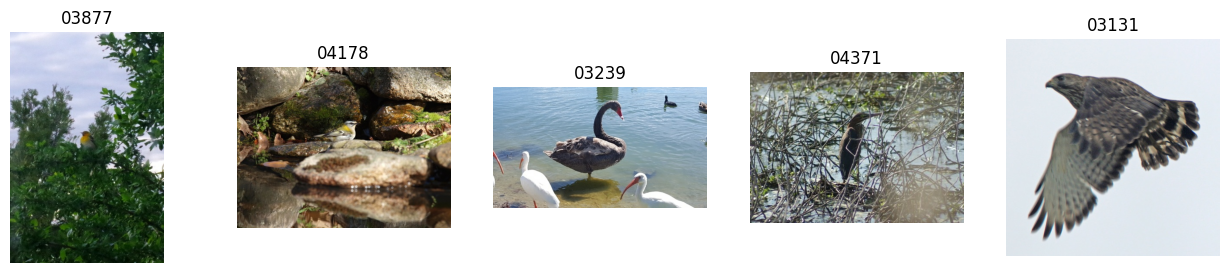

In [8]:
# Mostrar algunas imágenes de aves
archivos = list((BASE / "aves" / "train").rglob("*.jpg"))
fig, axs = plt.subplots(1, 5, figsize=(16, 3))
for ax, f in zip(axs, random.sample(archivos, 5)):
    ax.imshow(Image.open(f)); ax.set_title(f.parent.name); ax.axis("off")

In [9]:
# Solo borra los dos archivos .tar.gz, que ya no sirven una vez extraídas las aves. 
# No borra tus fotos de aves, esas quedan en C:\inat\aves.
(BASE / "train_mini.tar.gz").unlink()
(BASE / "val.tar.gz").unlink()

In [10]:
# "lee estas carpetas y trata cada carpeta como una especie distinta". 
# Con eso TensorFlow queda listo para entrenar un modelo que, dada una foto, adivine qué especie de ave es.
train_ds = tf.keras.utils.image_dataset_from_directory(
    BASE / "aves" / "train", image_size=(224, 224), batch_size=32)
val_ds = tf.keras.utils.image_dataset_from_directory(
    BASE / "aves" / "val", image_size=(224, 224), batch_size=32)

Found 74300 files belonging to 1486 classes.
Found 14860 files belonging to 1486 classes.


# Exploración basica

In [11]:
df_esp["genero"] = df_esp["especie"].str.split().str[0]

conteo = (df_esp.groupby("genero")
                .size()
                .sort_values(ascending=False)
                .rename("n_especies")
                .reset_index())

print("Géneros distintos:", len(conteo))
conteo

Géneros distintos: 648


,genero,n_especies
0,Setophaga,24
1,Calidris,19
2,Larus,17
3,Charadrius,17
4,Turdus,16
...,...,...
643,Vidua,1
644,Urocissa,1
645,Uria,1
646,Uraeginthus,1


In [15]:
top = conteo.head(20)

fig = px.bar(
    top.iloc[::-1],                     # invertido para que el mayor quede arriba
    x="n_especies", y="genero", orientation="h",
    text="n_especies",
    title="Top 20 géneros de aves por número de especies",
    labels={"n_especies": "Número de especies", "genero": "Género"},
)
fig.update_traces(textposition="outside")
fig.update_layout(height=600)
fig.show()

In [16]:
dist = (conteo["n_especies"].value_counts()
        .sort_index()
        .rename_axis("especies_por_genero")
        .reset_index(name="n_generos"))

fig = px.bar(
    dist, x="especies_por_genero", y="n_generos",
    text="n_generos",
    title="Distribución de géneros según su número de especies",
    labels={"especies_por_genero": "Especies por género",
            "n_generos": "Número de géneros"},
)
fig.update_traces(textposition="outside")
fig.update_xaxes(type="category")       # una barra por valor, sin huecos
fig.show()

In [17]:
fig = px.treemap(
    df_esp, path=["genero", "especie"],
    title="Géneros y especies de aves",
)
fig.update_layout(height=700)
fig.show()